# Fraud Detection: Classifying Card Transactions

The Fraud Prevention team reviews suspicious transactions mostly by hand, which no longer scales.
**Goal:** learn from the labelled 2025 history, build a model that flags fraudulent transactions,
and classify every transaction of January 2026.

Steps: data check → exploration → features and time-based split → models → decision thresholds → drift → explainability → January scoring.

## 1. Setup and data

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import lightgbm as lgb
import shap
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

SEED = 42
ROOT = Path("..")  # notebook lives in notebooks/
DATA_DIR = ROOT / "data" / "raw"
OUT_DIR = ROOT / "output"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.axisbelow": True, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "figure.dpi": 100})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

TARGET = "flag_fraude"
hist = pd.read_csv(DATA_DIR / "transacoes_historico_2025.csv", parse_dates=["datahora_transacao"])
jan = pd.read_csv(DATA_DIR / "transacoes_jan2026.csv", parse_dates=["datahora_transacao"])
hist[TARGET] = hist[TARGET].astype(int)
for df in (hist, jan):
    df["hour"] = df.datahora_transacao.dt.hour
    df["month"] = df.datahora_transacao.dt.month
    df["day"] = df.datahora_transacao.dt.day

print(f"2025 history: {hist.shape}, January 2026: {jan.shape}")
print(f"Missing values: {hist.isna().sum().sum()} / {jan.isna().sum().sum()} | duplicates: {hist.duplicated().sum()}")
print(f"Fraud: {hist[TARGET].sum():,} of {len(hist):,} transactions ({hist[TARGET].mean():.2%})")
print(f"Postal codes: {hist.codigo_postal.nunique():,} unique values (an ID, not a feature)")
hist.head(3)

2025 history: (523525, 18), January 2026: (44451, 17)


Missing values: 0 / 0 | duplicates: 0
Fraud: 20,485 of 523,525 transactions (3.91%)
Postal codes: 521,905 unique values (an ID, not a feature)


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,flag_fraude,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao,hour,month,day
0,2025-01-01 00:00:00,Pharmacy Z,Pharmacy,9.12,Cliente_16621,Recife,0,desktop,False,31.5,72519-282,562,madrugada,baixo,Nordeste,0,1,1
1,2025-01-01 00:01:00,Supermarket A,Supermarket,37.74,Cliente_12596,Recife,0,mobile,False,28.1,43549-179,461,madrugada,medio,Nordeste,0,1,1
2,2025-01-01 00:02:00,Restaurant Y,Food & Beverage,30.94,Cliente_10474,Salvador,0,mobile,True,29.1,68582-277,577,madrugada,medio,Nordeste,0,1,1


The data is clean. Three columns are dropped from modelling:

- `codigo_postal` is unique per row, so it is effectively an ID.
- `turno`, `valor_categoria` and `cidade_regiao` are recalculations of hour, amount and city.

With only 3.9% fraud, accuracy is meaningless, since approving everything is 96% "accurate".
Models are compared with **PR-AUC** (precision-recall AUC), which focuses on the rare fraud class.

## 2. Exploration

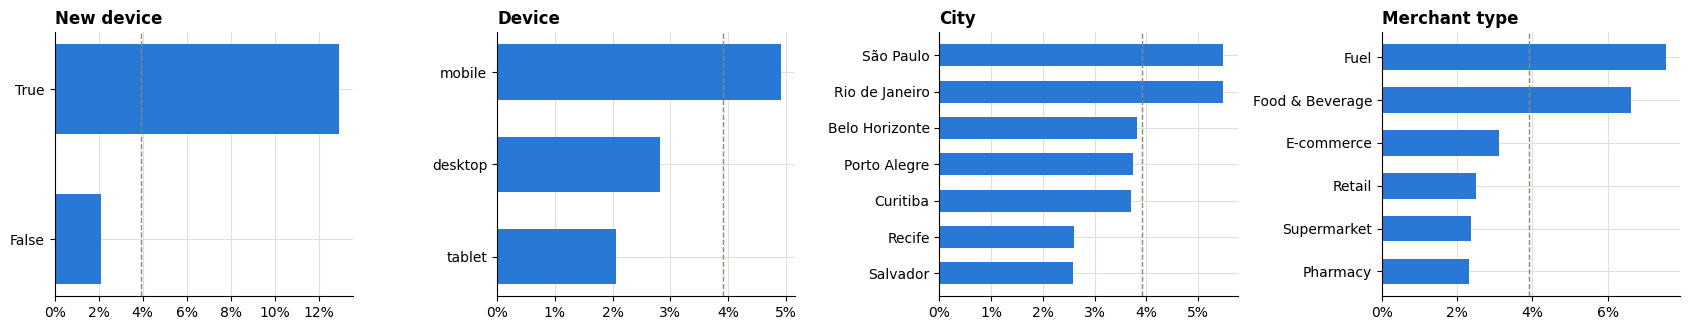

In [2]:
base = hist[TARGET].mean()
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, col, title in [(axes[0], "is_new_device", "New device"), (axes[1], "device_type", "Device"),
                       (axes[2], "cidade", "City"), (axes[3], "tipo_estabelecimento", "Merchant type")]:
    r = hist.groupby(col)[TARGET].mean().sort_values()
    ax.barh(r.index.astype(str), r.values, color=BLUE, height=0.6)
    ax.axvline(base, color=GRAY, ls="--", lw=1)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_title(title)
fig.tight_layout(); save(fig, "fraud_rate_by_category"); plt.show()

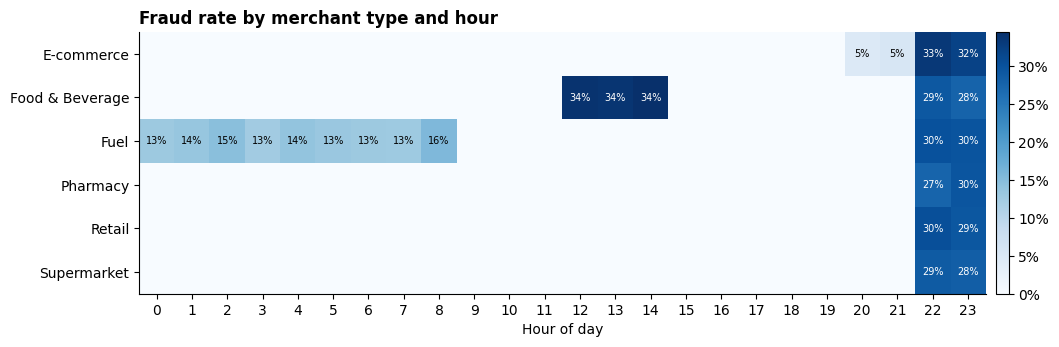

Risk windows hold 16% of transactions and 100% of frauds


In [3]:
heat = hist.pivot_table(index="tipo_estabelecimento", columns="hour", values=TARGET, aggfunc="mean")
fig, ax = plt.subplots(figsize=(13, 3.4))
im = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set_xticks(range(24)); ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index); ax.grid(False)
for (i, j), v in np.ndenumerate(heat.values):
    if v > 0:
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.2 else "black")
ax.set(xlabel="Hour of day", title="Fraud rate by merchant type and hour")
fig.colorbar(im, ax=ax, format=PercentFormatter(1, decimals=0), pad=0.01)
save(fig, "heatmap_hour_merchant"); plt.show()

in_window = heat.stack().loc[lambda s: s > 0].index
mask = pd.MultiIndex.from_arrays([hist.tipo_estabelecimento, hist.hour]).isin(in_window)
print(f"Risk windows hold {mask.mean():.0%} of transactions and {hist.loc[mask, TARGET].sum() / hist[TARGET].sum():.0%} of frauds")

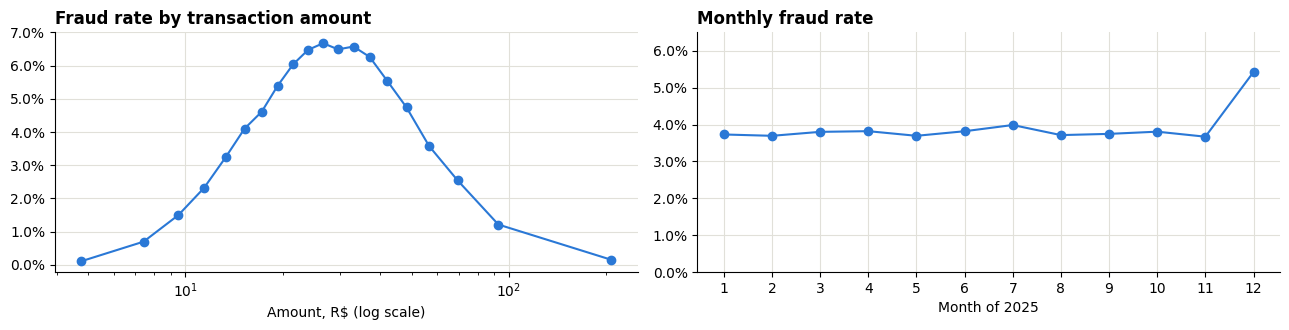

E-commerce fraud rate at 20h-23h, Jan-Nov vs December: 15% -> 60%
Columns with no signal (mean value, legitimate vs fraud):


,score_interno,temperatura_celsius
flag_fraude,,
0,500.4,24.0
1,499.3,23.7


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
amt = hist.groupby(pd.qcut(hist.valor_transacao, 20), observed=True).agg(rate=(TARGET, "mean"), mid=("valor_transacao", "median"))
axes[0].plot(amt.mid, amt.rate, marker="o", color=BLUE); axes[0].set_xscale("log")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set(xlabel="Amount, R$ (log scale)", title="Fraud rate by transaction amount")
m = hist.groupby("month")[TARGET].mean()
axes[1].plot(m.index, m.values, marker="o", color=BLUE); axes[1].set_ylim(0, 0.065)
axes[1].yaxis.set_major_formatter(PercentFormatter(1)); axes[1].set_xticks(range(1, 13))
axes[1].set(xlabel="Month of 2025", title="Monthly fraud rate")
fig.tight_layout(); save(fig, "amount_and_month"); plt.show()

ecom_night = hist[(hist.tipo_estabelecimento == "E-commerce") & (hist.hour >= 20)]
print("E-commerce fraud rate at 20h-23h, Jan-Nov vs December:",
      f"{ecom_night[ecom_night.month < 12][TARGET].mean():.0%} -> {ecom_night[ecom_night.month == 12][TARGET].mean():.0%}")
print("Columns with no signal (mean value, legitimate vs fraud):")
display(hist.groupby(TARGET)[["score_interno", "temperatura_celsius"]].mean().round(1))

**What the data shows**

- **Fraud only happens in specific (merchant type, hour) windows**: fuel at 0h–8h, food & beverage at 12h–14h,
  e-commerce at 20h–21h, and every merchant type at 22h–23h. These windows hold 16% of transactions and 100% of fraud.
- Inside them, risk rises with a **new device** (2% → 13% overall), **mobile**, **São Paulo / Rio**, and amounts around **R\$ 20–45**.
- **December shifted**: e-commerce fraud at 20h–23h jumped from 15% to 60%, lifting the monthly rate from 3.7% to 5.4%.
- **`score_interno` and temperature carry no signal**, as their averages are the same for fraud and legitimate transactions.
  Day of week and client-history features were also tested in an earlier version, with no meaningful gain.

These are interaction and non-linear patterns, which suits **tree-based models**.

## 3. Features and time-based split

Seven raw features, all available when a transaction is authorised.
The split follows time, since the model will always score *future* transactions:

| Set | Months | Use |
|---|---|---|
| Train | Jan–Sep 2025 | fit |
| Validation | Oct–Nov 2025 | early stopping, thresholds |
| Test | Dec 2025 | final, untouched evaluation |

In [5]:
CATS = ["tipo_estabelecimento", "nome_estabelecimento", "cidade", "device_type"]
FEATURES = ["hour", *CATS, "is_new_device", "valor_transacao"]

def make_X(df):
    X = df[FEATURES].copy()
    for c in CATS:
        X[c] = pd.Categorical(X[c], categories=sorted(hist[c].unique()))
    X["is_new_device"] = X.is_new_device.astype(int)
    return X

X, y = make_X(hist), hist[TARGET].to_numpy()
tr, va, te = (hist.month <= 9).to_numpy(), hist.month.isin([10, 11]).to_numpy(), (hist.month == 12).to_numpy()
print({name: f"{m.sum():,} rows, {y[m].mean():.2%} fraud" for name, m in [("train", tr), ("val", va), ("test", te)]})

{'train': '391,566 rows, 3.78% fraud', 'val': '87,508 rows, 3.74% fraud', 'test': '44,451 rows, 5.42% fraud'}


## 4. Models

| Model | Idea |
|---|---|
| **Rule baseline** | Score = training fraud rate of the transaction's (merchant type, hour) cell. What an analyst could build from a pivot table. |
| **Logistic regression** | Linear benchmark on one-hot categories and a quadratic in log-amount. |
| **LightGBM** | Gradient-boosted trees. Settings chosen by a small grid search on validation: 15 leaves, at least 500 rows per leaf. |
| **CatBoost** | Another boosting library with strong native categorical handling, as a robustness check. |

No class re-weighting is used, so the outputs remain calibrated probabilities, which the cost-based threshold in section 5 needs.

In [6]:
# Rule baseline
cell_rate = hist[tr].groupby(["tipo_estabelecimento", "hour"])[TARGET].mean()
rule = pd.MultiIndex.from_arrays([hist.tipo_estabelecimento, hist.hour]).map(cell_rate).fillna(0).to_numpy()

# Logistic regression
def lr_frame(X):
    Z = X.astype({c: str for c in CATS})
    Z["log_amt"] = np.log(Z.pop("valor_transacao"))
    Z["log_amt_sq"] = Z.log_amt ** 2
    return Z
logreg = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["hour", *CATS]),
                       ("num", StandardScaler(), ["is_new_device", "log_amt", "log_amt_sq"])]),
    LogisticRegression(max_iter=2000))
logreg.fit(lr_frame(X[tr]), y[tr])

# LightGBM
LGB_PARAMS = dict(learning_rate=0.03, num_leaves=15, min_child_samples=500, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)
lgbm = lgb.LGBMClassifier(n_estimators=3000, **LGB_PARAMS)
lgbm.fit(X[tr], y[tr], eval_set=[(X[va], y[va])], eval_metric="average_precision",
         callbacks=[lgb.early_stopping(150, verbose=False)])
N_TREES = lgbm.best_iteration_

# CatBoost
cat_X = X.astype({c: str for c in CATS})
catb = CatBoostClassifier(iterations=3000, learning_rate=0.05, depth=6, eval_metric="PRAUC", od_type="Iter",
                          od_wait=150, random_seed=SEED, verbose=0)
catb.fit(cat_X[tr], y[tr], cat_features=CATS, eval_set=(cat_X[va], y[va]), use_best_model=True)

scores = {
    "Rule baseline": rule,
    "Logistic regression": logreg.predict_proba(lr_frame(X))[:, 1],
    "LightGBM": lgbm.predict_proba(X)[:, 1],
    "CatBoost": catb.predict_proba(cat_X)[:, 1],
}
results = pd.DataFrame({name: {"val PR-AUC": average_precision_score(y[va], p[va]),
                               "test PR-AUC": average_precision_score(y[te], p[te]),
                               "test ROC-AUC": roc_auc_score(y[te], p[te])} for name, p in scores.items()}).T
results.round(3)

,val PR-AUC,test PR-AUC,test ROC-AUC
Rule baseline,0.310,0.310,0.865
Logistic regression,0.497,0.461,0.853
LightGBM,0.665,0.618,0.941
CatBoost,0.667,0.610,0.915


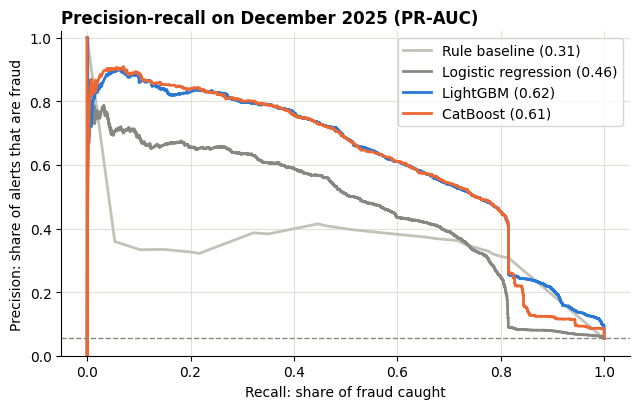

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for (name, p), c in zip(scores.items(), ["#c3c2b7", GRAY, BLUE, ORANGE]):
    prec, rec, _ = precision_recall_curve(y[te], p[te])
    ax.plot(rec, prec, color=c, lw=2, label=f"{name} ({average_precision_score(y[te], p[te]):.2f})")
ax.axhline(y[te].mean(), color=GRAY, ls="--", lw=1)
ax.set(xlabel="Recall: share of fraud caught", ylabel="Precision: share of alerts that are fraud",
       title="Precision-recall on December 2025 (PR-AUC)", ylim=(0, 1.02))
ax.legend(); fig.tight_layout(); save(fig, "pr_curves"); plt.show()

**LightGBM is selected.** It ties CatBoost on validation, but is the best on the December test month in both PR-AUC and ROC-AUC,
and it trains about 10× faster.
It roughly doubles the rule baseline's PR-AUC, because it combines the time windows with device, city and amount.
An earlier version also tried a LightGBM + CatBoost average, a logistic regression with hand-built window interactions,
and an unsupervised isolation forest. None beat LightGBM, and the isolation forest was close to random,
because fraud here does not look *unusual* one feature at a time.

## 5. From scores to decisions

- **Block threshold.** Chosen on validation to minimise *missed fraud amount + R\$ 10 per false block*.
  The R\$ 10 friction cost is an assumption to agree with the business.
- **Review threshold.** Chosen so that the high and medium bands together capture 95% of validation fraud.

| Band | Rule | Action |
|---|---|---|
| High | p ≥ block threshold | block or step-up authentication |
| Medium | review ≤ p < block | manual review |
| Low | p < review threshold | approve automatically |

In [8]:
FP_COST = 10
p_lgb, amount = scores["LightGBM"], hist.valor_transacao.to_numpy()

def total_cost(t, m):
    flag = p_lgb[m] >= t
    return amount[m][(y[m] == 1) & ~flag].sum() + FP_COST * ((y[m] == 0) & flag).sum()

T_BLOCK = min(np.arange(0.01, 0.91, 0.01).round(2), key=lambda t: total_cost(t, va))
_, rec, thr = precision_recall_curve(y[va], p_lgb[va])
T_REVIEW = thr[np.where(rec[:-1] >= 0.95)[0][-1]]
print(f"Block threshold {T_BLOCK:.2f} | review threshold {T_REVIEW:.3f}")

def risk_band(p):
    return np.select([p >= T_BLOCK, p >= T_REVIEW], ["High", "Medium"], default="Low")

def business_report(p, m):
    flag = p[m] >= T_BLOCK
    caught = (y[m] == 1) & flag
    fp = ((y[m] == 0) & flag).sum()
    return {"flag rate": flag.mean(), "recall": caught.sum() / y[m].sum(), "precision": caught.sum() / flag.sum(),
            "fraud R$ prevented": amount[m][caught].sum(), "false blocks": fp,
            "net benefit R$": amount[m][caught].sum() - FP_COST * fp}

display(pd.DataFrame({name: business_report(p, te) for name, p in scores.items()}).T.round(3))

bands = pd.DataFrame({"band": risk_band(p_lgb[te]), "fraud": y[te]}).groupby("band").fraud.agg(["size", "sum", "mean"])
bands.columns = ["transactions", "frauds", "fraud rate"]
bands["share of transactions"] = bands.transactions / bands.transactions.sum()
bands["share of frauds"] = bands.frauds / bands.frauds.sum()
bands.loc[["High", "Medium", "Low"]].round(3)

Block threshold 0.28 | review threshold 0.153


,flag rate,recall,precision,fraud R$ prevented,false blocks,net benefit R$
Rule baseline,0.095,0.654,0.373,48318.47,2647.0,21848.47
Logistic regression,0.045,0.462,0.560,33769.83,875.0,25019.83
LightGBM,0.057,0.628,0.593,45870.46,1039.0,35480.46
CatBoost,0.057,0.622,0.597,45597.78,1014.0,35457.78


,transactions,frauds,fraud rate,share of transactions,share of frauds
band,,,,,
High,2552,1513,0.593,0.057,0.628
Medium,1212,331,0.273,0.027,0.137
Low,40687,567,0.014,0.915,0.235


At the cost-optimal threshold, LightGBM blocks about 6% of December transactions and catches about 63% of fraud with about 59% precision.
Its net benefit ties CatBoost's, and is about 40% above logistic regression and 60% above the rule baseline.
About 91% of transactions are approved automatically, so analysts only see a small, fraud-dense review queue.
Most fraud that slips into the low band belongs to the new December e-commerce pattern, which section 6 addresses.

## 6. Handling the December drift

No model trained before December can know the new e-commerce pattern. Does recent data fix it?
Three setups are evaluated on **December 16–31**:

- **A**: train on Jan–Nov.
- **B**: also include Dec 1–15.
- **C**: like B, with December weighted 3×.

In [9]:
day, month = hist.day.to_numpy(), hist.month.to_numpy()
late_dec, early_dec = te & (day >= 16), te & (day < 16)
setups = {"A: Jan-Nov": (month <= 11, 1.0), "B: + Dec 1-15": ((month <= 11) | early_dec, 1.0),
          "C: B + 3x weight on December": ((month <= 11) | early_dec, 3.0)}
drift = {}
for name, (m, w) in setups.items():
    model = lgb.LGBMClassifier(n_estimators=N_TREES, **LGB_PARAMS)
    model.fit(X[m], y[m], sample_weight=np.where(month[m] == 12, w, 1.0))
    p = model.predict_proba(X[late_dec])[:, 1]
    drift[name] = {"PR-AUC": average_precision_score(y[late_dec], p), "ROC-AUC": roc_auc_score(y[late_dec], p)}
pd.DataFrame(drift).T.round(3)

,PR-AUC,ROC-AUC
A: Jan-Nov,0.629,0.939
B: + Dec 1-15,0.685,0.976
C: B + 3x weight on December,0.707,0.979


Two weeks of December data already help, and weighting recent data more helps further.
**The final model therefore trains on all of 2025 with December weighted 3×**, and in production it should be retrained monthly.

## 7. Explainability

SHAP values show how much each feature pushes a prediction up or down. This lets every flag be explained to an analyst.

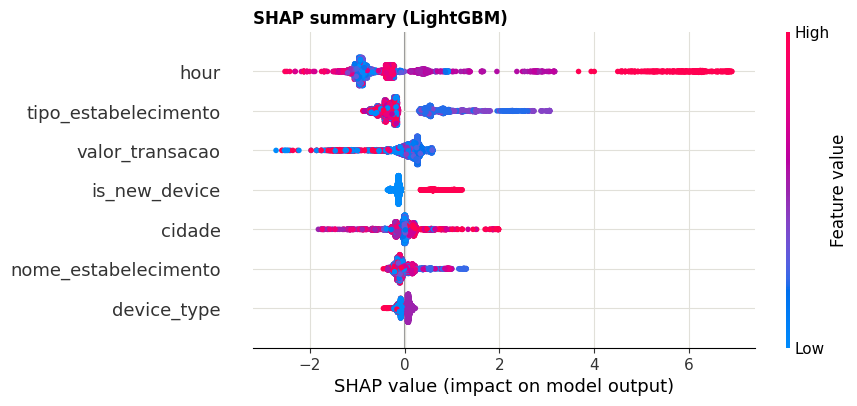

In [10]:
sample = X[te].sample(4000, random_state=SEED)
sv = shap.TreeExplainer(lgbm).shap_values(sample)
sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, sample.assign(**{c: sample[c].cat.codes for c in CATS}), show=False, plot_size=(9, 4))
plt.title("SHAP summary (LightGBM)", loc="left", fontweight="bold")
plt.gcf().savefig(FIG_DIR / "shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

Hour and merchant type dominate, which is the risk-window effect. Amount, new device, city and device type then refine the score.
A typical flag reads like this: *"new mobile device, 22h, R\$ 30, São Paulo"*.

## 8. Final model and January 2026 classification

The final model is refit on all of 2025, with December weighted 3×, and about 20% more trees for the larger dataset.
It reuses the validation thresholds and adds three columns to the original January file.

In [11]:
final = lgb.LGBMClassifier(n_estimators=int(N_TREES * 1.2), **LGB_PARAMS)
final.fit(X, y, sample_weight=np.where(month == 12, 3.0, 1.0))

p_jan = final.predict_proba(make_X(jan))[:, 1]
out = pd.read_csv(DATA_DIR / "transacoes_jan2026.csv")
out["fraud_probability"] = p_jan.round(6)
out["fraud_prediction"] = p_jan >= T_BLOCK
out["risk_band"] = risk_band(p_jan)
out.to_csv(OUT_DIR / "transacoes_jan2026_classified.csv", index=False)

assert len(out) == 44_451 and out.fraud_probability.notna().all()
print(f"Expected fraud rate (mean probability): {p_jan.mean():.2%}")
print(f"Classified as fraud: {out.fraud_prediction.sum():,} ({out.fraud_prediction.mean():.2%})")
out.risk_band.value_counts(normalize=True).loc[["High", "Medium", "Low"]].round(3)

Expected fraud rate (mean probability): 4.10%
Classified as fraud: 2,727 (6.13%)


risk_band
High      0.061
Medium    0.025
Low       0.913
Name: proportion, dtype: float64

## 9. Conclusions

- **Fraud is concentrated** in a few (merchant type, hour) windows. A new device, mobile, São Paulo / Rio and R\$ 20–45 amounts raise the risk inside them.
  **`score_interno` has no predictive value**, which is worth raising if the current process relies on it.
- **LightGBM is the best model.** On held-out December it scores PR-AUC 0.62 and ROC-AUC 0.94, against 0.46 and 0.85 for logistic regression.
  It catches about 63% of fraud at about 59% precision, with the highest net benefit.
- **Three risk bands** let 91% of transactions be approved automatically, with under 3% sent to manual review.
- **January 2026**: about 6% are classified as fraud, 2.5% go to review, and the expected fraud rate is about 4.1%.

**Limitations.** The data looks synthetic, with zero fraud outside the windows and one transaction per minute.
The R\$ 10 cost of a false block is an assumption.
If December's e-commerce night fraud persists, the model still under-scores it.

**Next steps.**

1. Monitor weekly by merchant type and hour.
2. Retrain monthly with recency weighting.
3. Agree the costs with the business.
4. Run in shadow mode next to the manual process before automating.